In [1]:
import os, sys
os.chdir("..")                 # subir a la raíz del proyecto (para que encuentre data/)
sys.path.append("src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from state import obtener_mensajes, construir_estado, estado_a_dataframes
from transform import unir_anios, MAPEO, COLUMNAS_COMUNES

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

os.makedirs("figuras", exist_ok=True)

def guardar_figura(nombre):
    plt.savefig(f"figuras/{nombre}.png", dpi=150, bbox_inches="tight")

cargo el estado se usa la copia local, sin volver a Kafka

In [2]:
mensajes = obtener_mensajes()
estado, duplicados = construir_estado(mensajes)
dfs = estado_a_dataframes(estado)

for anio, df in dfs.items():
    print(anio, df.shape)
dfs[2015].head()

Cargando mensajes desde la copia local: data\raw_messages.json
2015 (158, 15)
2016 (157, 16)
2017 (155, 15)
2018 (156, 12)
2019 (156, 12)


,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual,year,source_file,record_id
0,Denmark,Western Europe,3,7.527,0.03328,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139,2.49204,2015,2015.csv,2015-3
1,Canada,North America,5,7.427,0.03553,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811,2.45176,2015,2015.csv,2015-5
2,Israel,Middle East and Northern Africa,11,7.278,0.03470,1.22857,1.22393,0.91387,0.41319,0.07785,0.33172,3.08854,2015,2015.csv,2015-11
3,Brazil,Latin America and Caribbean,16,6.983,0.04076,0.98124,1.23287,0.69702,0.49049,0.17521,0.14574,3.26001,2015,2015.csv,2015-16
4,Oman,Middle East and Northern Africa,22,6.853,0.05335,1.36011,1.08182,0.76276,0.63274,0.32524,0.21542,2.47489,2015,2015.csv,2015-22


miro cómo viene un mensaje, con su metadata de Kafka y los campos originales del csv, y cómo se reparten por archivo y por partición

In [3]:
import json

print(json.dumps(mensajes[0], indent=2, default=str))

print("\nMensajes por archivo de origen:")
print(pd.Series([m["value"]["metadata"]["source_file"] for m in mensajes]).value_counts().sort_index())

print("\nMensajes por partición:")
print(pd.Series([m["partition"] for m in mensajes]).value_counts().sort_index())

{
  "partition": 0,
  "offset": 1,
  "timestamp": 1794769254624,
  "key": "2015-3",
  "value": {
    "metadata": {
      "source_file": "2015.csv",
      "year": 2015,
      "record_id": "2015-3"
    },
    "data": {
      "Country": "Denmark",
      "Region": "Western Europe",
      "Happiness Rank": 3,
      "Happiness Score": 7.527,
      "Standard Error": 0.03328,
      "Economy (GDP per Capita)": 1.32548,
      "Family": 1.36058,
      "Health (Life Expectancy)": 0.87464,
      "Freedom": 0.64938,
      "Trust (Government Corruption)": 0.48357,
      "Generosity": 0.34139,
      "Dystopia Residual": 2.49204
    }
  }
}

Mensajes por archivo de origen:
2015.csv    158
2016.csv    157
2017.csv    155
2018.csv    156
2019.csv    156
Name: count, dtype: int64

Mensajes por partición:
0    228
1    269
2    285
Name: count, dtype: int64


verifico que lo que consumí coincide con lo que quedó en el estado

In [4]:
from state import verificar_estado

verificar_estado(mensajes, estado, duplicados, dfs)


===== VERIFICACIÓN DEL ESTADO =====
Mensajes consumidos: 782
Registros únicos en el estado: 782
Mensajes duplicados descartados: 0
Suma de filas de los DataFrames: 782

Registros por año:
  2015 (2015.csv): 158 filas, 12 columnas de datos
  2016 (2016.csv): 157 filas, 13 columnas de datos
  2017 (2017.csv): 155 filas, 12 columnas de datos
  2018 (2018.csv): 156 filas, 9 columnas de datos
  2019 (2019.csv): 156 filas, 9 columnas de datos

Columnas de datos por año:

  2015: ['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']

  2016: ['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']

  2017: ['Country', 'Happin

dejo las columnas que son las mismas en todos los años columnas comunes y únicas

In [5]:
cols_por_anio = {
    a: set(df.columns) - {"year", "source_file", "record_id"} for a, df in dfs.items()
}
comunes_originales = set.intersection(*cols_por_anio.values())
print("Columnas con el MISMO nombre en los 5 años:", comunes_originales)

todas = set.union(*cols_por_anio.values())
tabla = pd.DataFrame(
    {a: [c in cols for c in sorted(todas)] for a, cols in cols_por_anio.items()},
    index=sorted(todas),
)
display(tabla.replace({True: "✔", False: "–"}))

Columnas con el MISMO nombre en los 5 años: {'Generosity'}


,2015,2016,2017,2018,2019
Country,✔,✔,✔,–,–
Country or region,–,–,–,✔,✔
Dystopia Residual,✔,✔,–,–,–
Dystopia.Residual,–,–,✔,–,–
Economy (GDP per Capita),✔,✔,–,–,–
Economy..GDP.per.Capita.,–,–,✔,–,–
Family,✔,✔,✔,–,–
Freedom,✔,✔,✔,–,–
Freedom to make life choices,–,–,–,✔,✔
GDP per capita,–,–,–,✔,✔


armonizo, descarto y unifico

In [6]:
df_all, descartadas = unir_anios(dfs)

print("Dataset unificado:", df_all.shape)
print("\nColumnas descartadas por año (no comunes a los 5 años):")
for anio, cols in descartadas.items():
    print(f"  {anio}: {cols}")

df_all.info()
df_all.head()

Dataset unificado: (782, 10)

Columnas descartadas por año (no comunes a los 5 años):
  2015: ['Region', 'Happiness Rank', 'Standard Error', 'Dystopia Residual']
  2016: ['Region', 'Happiness Rank', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Dystopia Residual']
  2017: ['Happiness.Rank', 'Whisker.high', 'Whisker.low', 'Dystopia.Residual']
  2018: ['Overall rank']
  2019: ['Overall rank']
<class 'pandas.DataFrame'>
RangeIndex: 782 entries, 0 to 781
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   country                782 non-null    str    
 1   happiness_score        782 non-null    float64
 2   gdp_per_capita         782 non-null    float64
 3   social_support         782 non-null    float64
 4   life_expectancy        782 non-null    float64
 5   freedom                782 non-null    float64
 6   generosity             782 non-null    float64
 7   corruption_perception  781

,country,happiness_score,gdp_per_capita,social_support,life_expectancy,freedom,generosity,corruption_perception,year,record_id
0,Denmark,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357,2015,2015-3
1,Canada,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957,2015,2015-5
2,Israel,7.278,1.22857,1.22393,0.91387,0.41319,0.33172,0.07785,2015,2015-11
3,Brazil,6.983,0.98124,1.23287,0.69702,0.49049,0.14574,0.17521,2015,2015-16
4,Oman,6.853,1.36011,1.08182,0.76276,0.63274,0.21542,0.32524,2015,2015-22


doy calidad a los datos limpieza de nulos, duplicados y rangos

In [7]:
print("Nulos por columna:")
print(df_all.isnull().sum())

print("\nFilas con nulos:")
display(df_all[df_all.isnull().any(axis=1)])

print("\nDuplicados exactos:", df_all.duplicated().sum())
print("Países repetidos dentro de un mismo año:",
      df_all.duplicated(subset=["country", "year"]).sum())

print("\nEstadísticas descriptivas por año (happiness_score):")
display(df_all.groupby("year")["happiness_score"].describe())

display(df_all.drop(columns=["country", "record_id"]).describe().T)
print("Nulos por columna:")
print(df_all.isnull().sum())

print("\nFilas con nulos:")
display(df_all[df_all.isnull().any(axis=1)])

print("\nDuplicados exactos:", df_all.duplicated().sum())
print("Países repetidos dentro de un mismo año:",
      df_all.duplicated(subset=["country", "year"]).sum())

print("\nEstadísticas descriptivas por año (happiness_score):")
display(df_all.groupby("year")["happiness_score"].describe())

display(df_all.drop(columns=["country", "record_id"]).describe().T)

Nulos por columna:
country                  0
happiness_score          0
gdp_per_capita           0
social_support           0
life_expectancy          0
freedom                  0
generosity               0
corruption_perception    1
year                     0
record_id                0
dtype: int64

Filas con nulos:


,country,happiness_score,gdp_per_capita,social_support,life_expectancy,freedom,generosity,corruption_perception,year,record_id
525,United Arab Emirates,6.774,2.096,0.776,0.67,0.284,0.186,NaN,2018,2018-20



Duplicados exactos: 0
Países repetidos dentro de un mismo año: 0

Estadísticas descriptivas por año (happiness_score):


,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2015,158.0,5.375734,1.145010,2.839,4.52600,5.2325,6.24375,7.587
2016,157.0,5.382185,1.141674,2.905,4.40400,5.3140,6.26900,7.526
2017,155.0,5.354019,1.131230,2.693,4.50550,5.2790,6.10150,7.537
2018,156.0,5.375917,1.119506,2.905,4.45375,5.3780,6.16850,7.632
2019,156.0,5.407096,1.113120,2.853,4.54450,5.3795,6.18450,7.769


,count,mean,std,min,25%,50%,75%,max
happiness_score,782.0,5.379018,1.127456,2.693,4.509750,5.322000,6.189500,7.769000
gdp_per_capita,782.0,0.916047,0.407340,0.000,0.606500,0.982205,1.236187,2.096000
social_support,782.0,1.078392,0.329548,0.000,0.869363,1.124735,1.327250,1.644000
life_expectancy,782.0,0.612416,0.248309,0.000,0.440183,0.647310,0.808000,1.141000
freedom,782.0,0.411091,0.152880,0.000,0.309768,0.431000,0.531000,0.724000
generosity,782.0,0.218576,0.122321,0.000,0.130000,0.201982,0.278832,0.838075
corruption_perception,781.0,0.125436,0.105816,0.000,0.054000,0.091000,0.156030,0.551910
year,782.0,2016.993606,1.417364,2015.000,2016.000000,2017.000000,2018.000000,2019.000000


Nulos por columna:
country                  0
happiness_score          0
gdp_per_capita           0
social_support           0
life_expectancy          0
freedom                  0
generosity               0
corruption_perception    1
year                     0
record_id                0
dtype: int64

Filas con nulos:


,country,happiness_score,gdp_per_capita,social_support,life_expectancy,freedom,generosity,corruption_perception,year,record_id
525,United Arab Emirates,6.774,2.096,0.776,0.67,0.284,0.186,NaN,2018,2018-20



Duplicados exactos: 0
Países repetidos dentro de un mismo año: 0

Estadísticas descriptivas por año (happiness_score):


,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2015,158.0,5.375734,1.145010,2.839,4.52600,5.2325,6.24375,7.587
2016,157.0,5.382185,1.141674,2.905,4.40400,5.3140,6.26900,7.526
2017,155.0,5.354019,1.131230,2.693,4.50550,5.2790,6.10150,7.537
2018,156.0,5.375917,1.119506,2.905,4.45375,5.3780,6.16850,7.632
2019,156.0,5.407096,1.113120,2.853,4.54450,5.3795,6.18450,7.769


,count,mean,std,min,25%,50%,75%,max
happiness_score,782.0,5.379018,1.127456,2.693,4.509750,5.322000,6.189500,7.769000
gdp_per_capita,782.0,0.916047,0.407340,0.000,0.606500,0.982205,1.236187,2.096000
social_support,782.0,1.078392,0.329548,0.000,0.869363,1.124735,1.327250,1.644000
life_expectancy,782.0,0.612416,0.248309,0.000,0.440183,0.647310,0.808000,1.141000
freedom,782.0,0.411091,0.152880,0.000,0.309768,0.431000,0.531000,0.724000
generosity,782.0,0.218576,0.122321,0.000,0.130000,0.201982,0.278832,0.838075
corruption_perception,781.0,0.125436,0.105816,0.000,0.054000,0.091000,0.156030,0.551910
year,782.0,2016.993606,1.417364,2015.000,2016.000000,2017.000000,2018.000000,2019.000000


limpieza y exploración de datos, deteccion de Outliers utilizando el método del Rango Intercuartílico. 

Los nombres de columnas difieren entre años y se armonizaron a un esquema común, se detectaron 6 países con nombre inconsistente entre años, que se unificaron, hay 1 valor nulo UAE 2018, corruption_perception que se imputa con la mediana dentro del Pipeline tener en cuenta corruption_perception presenta 67 outliers por IQR, producto de una distribución asimétrica, se conservan por ser valores reales y no hay duplicados.

,variable,outliers_IQR,límite_inf,límite_sup
0,happiness_score,0,1.990,8.709
1,gdp_per_capita,0,-0.338,2.181
2,social_support,10,0.183,2.014
3,life_expectancy,0,-0.112,1.360
4,freedom,0,-0.022,0.863
5,generosity,17,-0.093,0.502
6,corruption_perception,67,-0.099,0.309


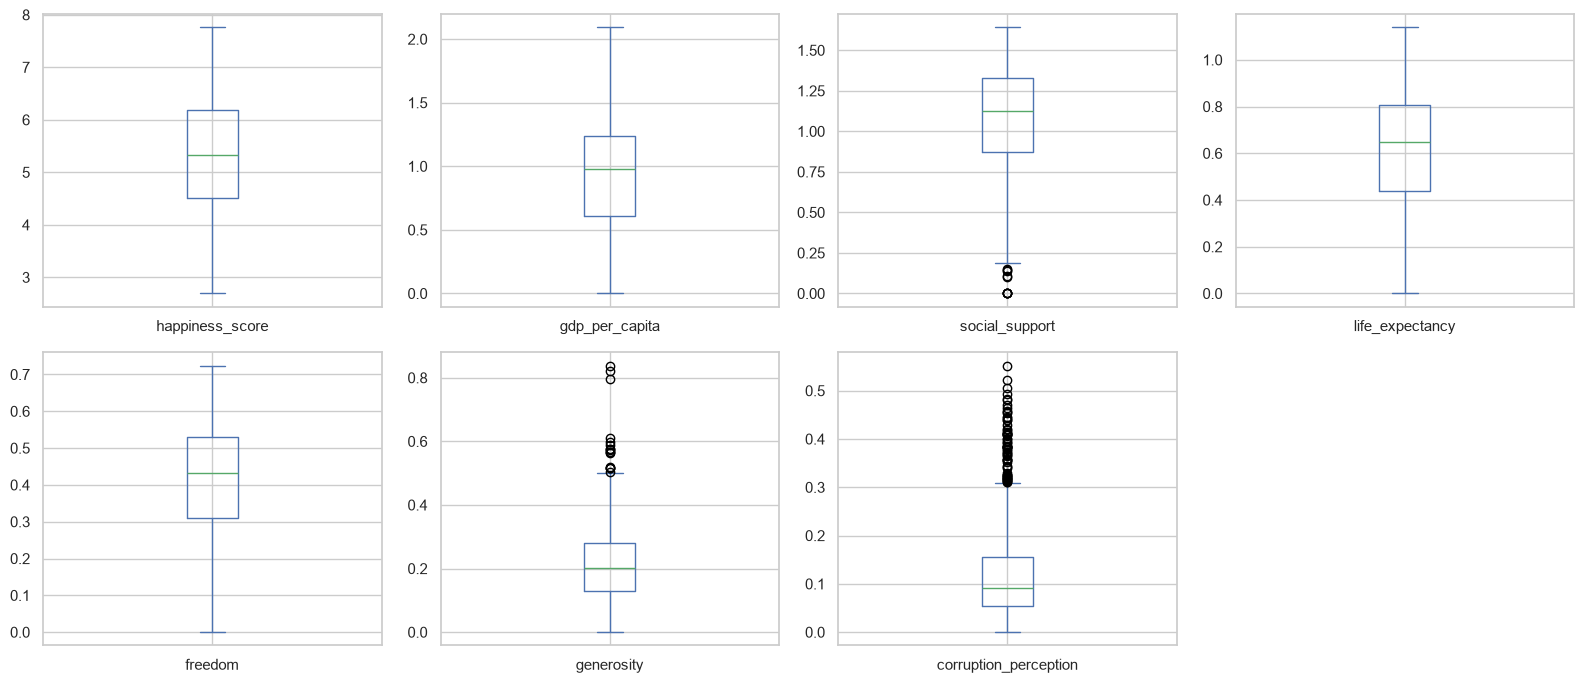

Países en los 5 años: 146 | países en solo algunos: 18


,2015,2016,2017,2018,2019
Angola,✔,✔,✔,✔,–
Belize,–,✔,✔,✔,–
Central African Republic,✔,–,✔,✔,✔
Comoros,✔,✔,–,–,✔
Djibouti,✔,–,–,–,–
Gambia,–,–,–,–,✔
Laos,✔,✔,–,✔,✔
Lesotho,✔,–,✔,✔,✔
Mozambique,✔,–,✔,✔,✔
Namibia,–,✔,✔,✔,✔


In [8]:
# Outliers por variable
numericas = [c for c in COLUMNAS_COMUNES if c != "country"]
resumen = []
for col in numericas:
    q1, q3 = df_all[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df_all[col] < low) | (df_all[col] > high)).sum()
    resumen.append({"variable": col, "outliers_IQR": n, "límite_inf": round(low, 3), "límite_sup": round(high, 3)})
display(pd.DataFrame(resumen))

df_all[numericas].plot(kind="box", subplots=True, layout=(2, 4), figsize=(16, 7), sharey=False)
plt.tight_layout()
guardar_figura("01_boxplots_outliers")
plt.show()

# Países que no aparecen en los 5 años (posibles nombres inconsistentes)
paises_por_anio = {a: set(g["country"]) for a, g in df_all.groupby("year")}
en_todos = set.intersection(*paises_por_anio.values())
en_alguno = set.union(*paises_por_anio.values())
parciales = sorted(en_alguno - en_todos)

presencia = pd.DataFrame(
    {a: [p in s for p in parciales] for a, s in paises_por_anio.items()}, index=parciales
)
print(f"Países en los 5 años: {len(en_todos)} | países en solo algunos: {len(parciales)}")
display(presencia.replace({True: "✔", False: "–"}))

usar variables de todos los años: GDP, apoyo social, esperanza de vida, libertad, generosidad, percepción de corrupción, más el país

In [9]:
cols_cero = ["gdp_per_capita", "social_support", "life_expectancy", "freedom", "generosity", "corruption_perception"]

ceros = (df_all[cols_cero] == 0).sum()
print("Cantidad de ceros por variable:")
print(ceros)

mask = (df_all[cols_cero] == 0).any(axis=1)
display(df_all.loc[mask, ["country", "year"] + cols_cero].sort_values(["country", "year"]))

Cantidad de ceros por variable:
gdp_per_capita           5
social_support           5
life_expectancy          5
freedom                  5
generosity               5
corruption_perception    6
dtype: int64


,country,year,gdp_per_capita,social_support,life_expectancy,freedom,generosity,corruption_perception
780,Afghanistan,2019,0.350000,0.517000,0.361000,0.000000,0.158000,0.025000
461,Angola,2017,0.858428,1.104412,0.049869,0.000000,0.097926,0.069720
514,Angola,2018,0.730000,1.125000,0.269000,0.000000,0.079000,0.061000
288,Bosnia and Herzegovina,2016,0.933830,0.643670,0.707660,0.095110,0.298890,0.000000
387,Bosnia and Herzegovina,2017,0.982409,1.069336,0.705186,0.204403,0.328867,0.000000
597,Bosnia and Herzegovina,2018,0.915000,1.078000,0.758000,0.280000,0.216000,0.000000
153,Central African Republic,2015,0.078500,0.000000,0.066990,0.488790,0.238350,0.082890
411,Central African Republic,2017,0.000000,0.000000,0.018773,0.270842,0.280876,0.056565
625,Central African Republic,2018,0.024000,0.000000,0.010000,0.305000,0.218000,0.038000
723,Central African Republic,2019,0.026000,0.000000,0.105000,0.225000,0.235000,0.035000


miro cómo se distribuye el puntaje y cómo se mueve año a año

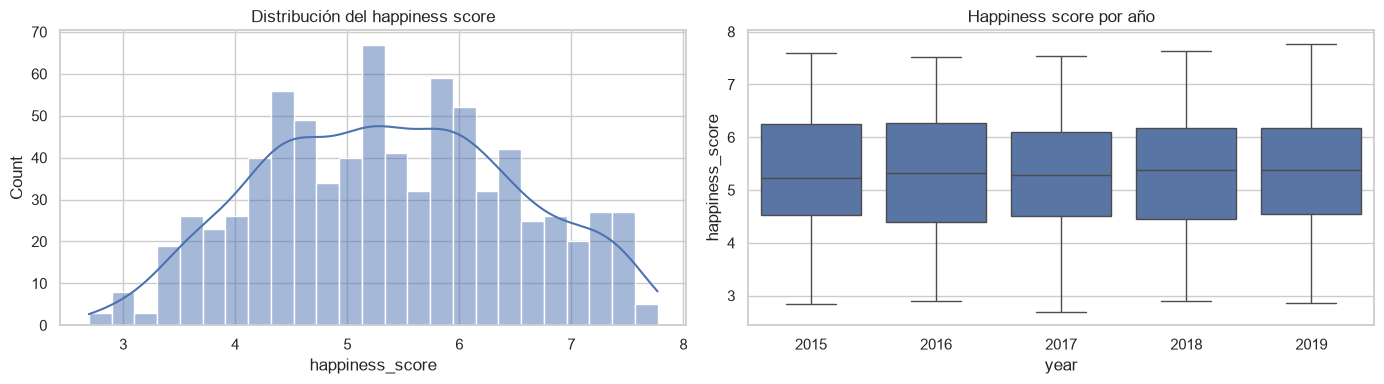

,happiness_score,gdp_per_capita,social_support,life_expectancy,freedom,generosity,corruption_perception
year,,,,,,,
2015,5.376,0.846,0.991,0.630,0.429,0.237,0.143
2016,5.382,0.954,0.794,0.558,0.371,0.243,0.138
2017,5.354,0.985,1.189,0.551,0.409,0.247,0.123
2018,5.376,0.891,1.213,0.597,0.455,0.181,0.112
2019,5.407,0.905,1.209,0.725,0.393,0.185,0.111


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df_all["happiness_score"], bins=25, kde=True, ax=ax[0])
ax[0].set_title("Distribución del happiness score")

sns.boxplot(data=df_all, x="year", y="happiness_score", ax=ax[1])
ax[1].set_title("Happiness score por año")

plt.tight_layout()
guardar_figura("02_distribucion_por_anio")
plt.show()

display(df_all.groupby("year")[numericas].mean().round(3))

reviso qué tan relacionada está cada variable con el puntaje

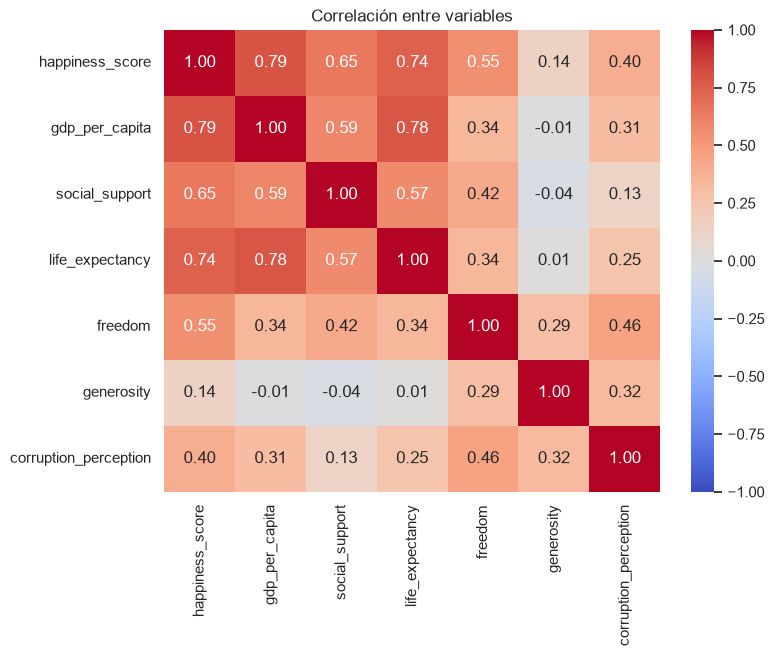

Correlación de cada variable con happiness_score:


gdp_per_capita           0.789
life_expectancy          0.742
social_support           0.649
freedom                  0.551
corruption_perception    0.398
generosity               0.138
Name: happiness_score, dtype: float64

In [11]:
corr = df_all[numericas].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables")
guardar_figura("03_correlacion")
plt.show()

print("Correlación de cada variable con happiness_score:")
display(corr["happiness_score"].drop("happiness_score").sort_values(ascending=False).round(3))

grafico cada variable contra el puntaje para ver si la relación se parece a una línea

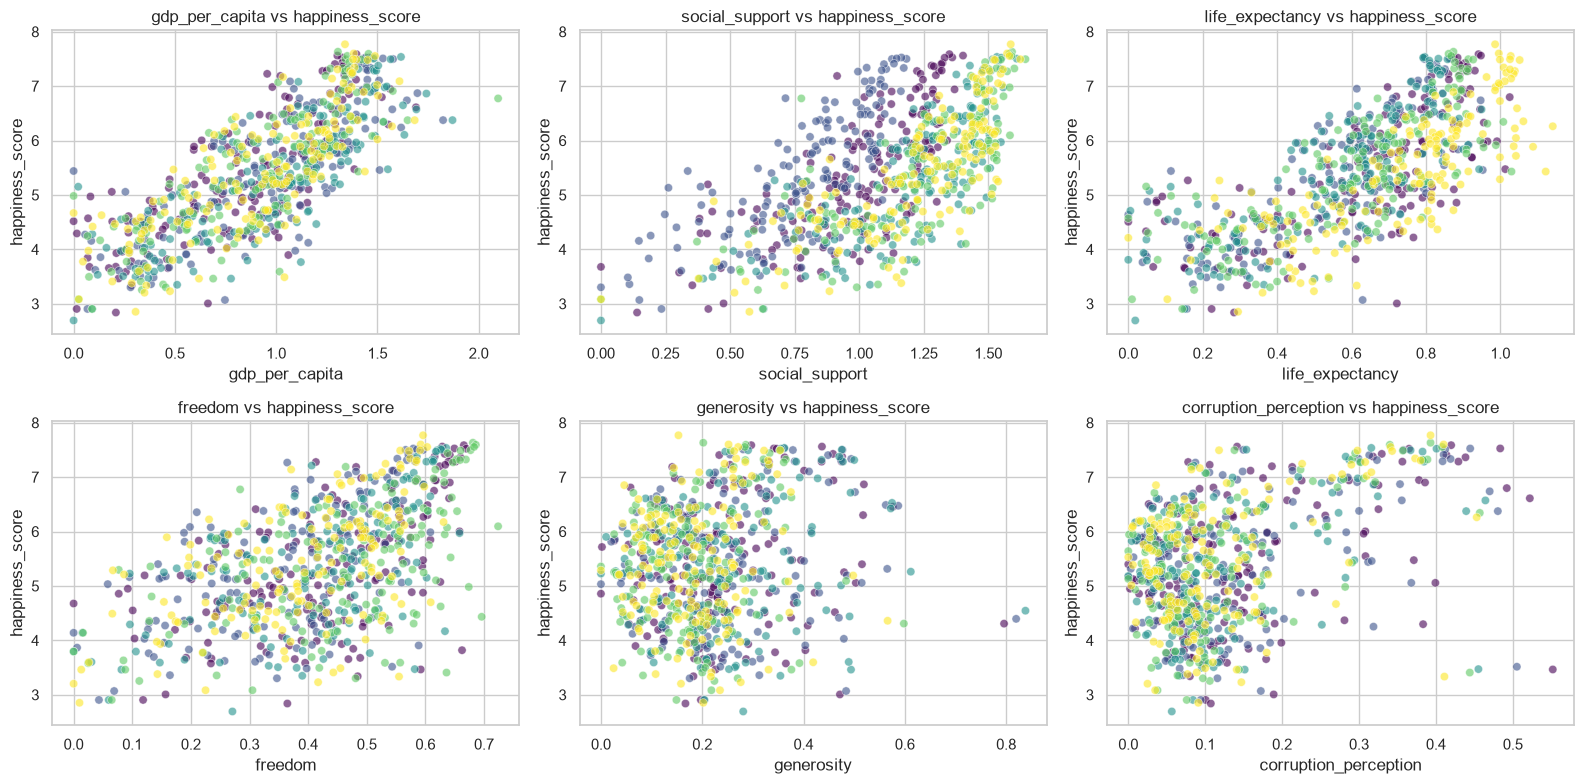

In [12]:
predictoras = [c for c in numericas if c != "happiness_score"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, predictoras):
    sns.scatterplot(data=df_all, x=col, y="happiness_score", hue="year", palette="viridis", alpha=0.6, ax=ax)
    ax.set_title(f"{col} vs happiness_score")
    ax.legend([], [], frameon=False)
plt.tight_layout()
guardar_figura("04_dispersion")
plt.show()

dejo aparte pib, apoyo social y esperanza de vida para ver cómo se relacionan entre ellas

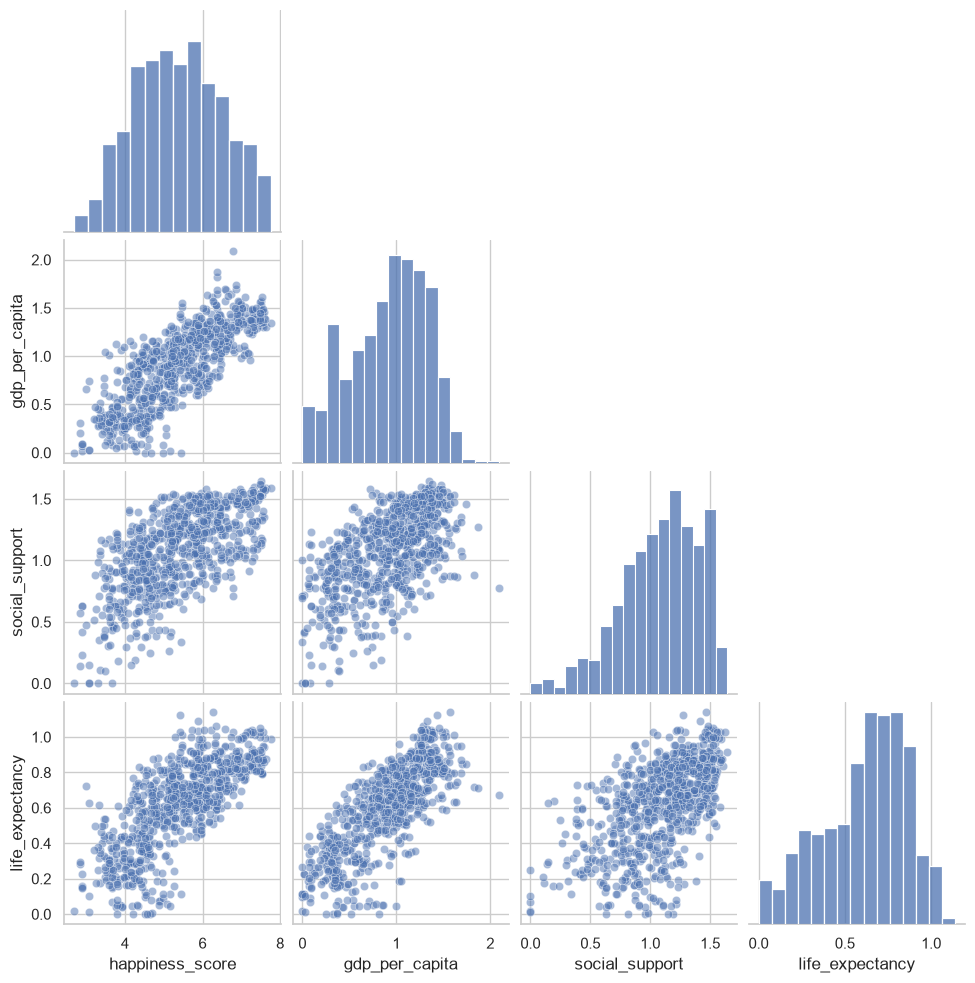

In [13]:
g = sns.pairplot(df_all[["happiness_score", "gdp_per_capita", "social_support", "life_expectancy"]],
                 corner=True, plot_kws={"alpha": 0.5})
g.savefig("figuras/07_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

el nulo de UAE 2018 lo dejo así porque lo imputo con la mediana dentro del pipeline, aprendida solo con train. guardo el dataset unificado para tenerlo a mano

In [14]:
print("Nulos antes del modelado:")
print(df_all[predictoras].isnull().sum())

print("\nObservaciones por país:")
print(df_all["country"].value_counts().describe())

df_all.to_csv("data/dataset_unificado.csv", index=False)
print("\nGuardado: data/dataset_unificado.csv", df_all.shape)

Nulos antes del modelado:
gdp_per_capita           0
social_support           0
life_expectancy          0
freedom                  0
generosity               0
corruption_perception    1
dtype: int64

Observaciones por país:
count    164.000000
mean       4.768293
std        0.780102
min        1.000000
25%        5.000000
50%        5.000000
75%        5.000000
max        5.000000
Name: count, dtype: float64

Guardado: data/dataset_unificado.csv (782, 10)


hallazgos del eda. El puntaje va de 2.7 a 7.8 con forma parecida a una campana y casi no cambia de un año a otro, la media va de 5.35 a 5.41, así que apilar los años tiene sentido. Las variables más relacionadas con el puntaje son el pib con 0.79, la esperanza de vida con 0.74 y el apoyo social con 0.65. La libertad llega a 0.55, la corrupción a 0.40 y la generosidad apenas a 0.14. El pib y la esperanza de vida están bastante correlacionadas entre sí, con 0.78, y el apoyo social se relaciona con las dos en cerca de 0.58. Más adelante miro el VIF y el KMO para ver si eso es un problema. En las dispersiones la relación del pib, la esperanza de vida y el apoyo social con el puntaje se ve bastante lineal, lo que justifica probar una regresión lineal.

hallazgo importante. Algunas variables cambian de escala entre años. El apoyo social promedio pasa de 0.79 en 2016 a 1.19 en 2017 y la esperanza de vida sube a 0.73 en 2019, y se nota en las dispersiones porque los años se separan por colores. Probablemente es un cambio de definición entre ediciones del informe. Más adelante lo compruebo con una prueba estadística y lo trato metiendo el año en el modelo.

sobre la integración, apilé los cinco años en un solo dataset con las columnas comunes. Gano observaciones, pero un mismo país aparece hasta cinco veces y pierdo lo que solo existe en algunos años

dejo definidas las variables predictoras y el objetivo. Me quedo con las seis variables comunes a los cinco años. La generosidad tiene la correlación más baja con 0.14, pero son pocas variables, no hay problema de dimensión y el modelo le da un peso pequeño, así que por ahora no la quito y más adelante veo en la regresión si aporta. El ranking, el error estándar, los intervalos y el dystopia residual quedan fuera por las razones de la armonización

In [15]:
FEATURES = ["gdp_per_capita", "social_support", "life_expectancy",
            "freedom", "generosity", "corruption_perception"]
TARGET = "happiness_score"

print("Features:", FEATURES)
print("Target:", TARGET)
print("Filas:", len(df_all))

Features: ['gdp_per_capita', 'social_support', 'life_expectancy', 'freedom', 'generosity', 'corruption_perception']
Target: happiness_score
Filas: 782


separo train y test por país, así un mismo país no queda en los dos lados y las métricas no salen infladas

In [16]:
from sklearn.model_selection import GroupShuffleSplit

X = df_all[FEATURES]
y = df_all[TARGET]
grupos = df_all["country"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_train, idx_test = next(gss.split(X, y, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
y_train, y_test = y.iloc[idx_train], y.iloc[idx_test]
g_train = grupos.iloc[idx_train]

paises_train, paises_test = set(grupos.iloc[idx_train]), set(grupos.iloc[idx_test])
print("Filas train:", len(X_train), "| Filas test:", len(X_test))
print("Países train:", len(paises_train), "| Países test:", len(paises_test))
print("Países en ambos conjuntos:", len(paises_train & paises_test), "-> tiene que ser 0")

Filas train: 626 | Filas test: 156
Países train: 131 | Países test: 33
Países en ambos conjuntos: 0 -> tiene que ser 0


armo un pipeline por modelo con imputación y escalado, y comparo regresión lineal con random forest usando validación cruzada solo sobre train

In [17]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_validate

modelos = {
    "Regresión Lineal": Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
        ("modelo", LinearRegression()),
    ]),
    "Random Forest": Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
        ("modelo", RandomForestRegressor(n_estimators=200, random_state=42)),
    ]),
}

cv = GroupKFold(n_splits=5)
filas = []
for nombre, pipe in modelos.items():
    r = cross_validate(pipe, X_train, y_train, groups=g_train, cv=cv,
                       scoring=["r2", "neg_root_mean_squared_error"])
    filas.append({
        "modelo": nombre,
        "R2_cv": r["test_r2"].mean(),
        "RMSE_cv": -r["test_neg_root_mean_squared_error"].mean(),
    })
display(pd.DataFrame(filas).round(4))

,modelo,R2_cv,RMSE_cv
0,Regresión Lineal,0.7170,0.5652
1,Random Forest,0.6847,0.6056


entreno con todo train y evalúo en test

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def r2_ajustado(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

resultados, predicciones = [], {}
for nombre, pipe in modelos.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    predicciones[nombre] = pred

    mse = mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    resultados.append({
        "modelo": nombre,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2,
        "R2_ajustado": r2_ajustado(r2, len(y_test), len(FEATURES)),
    })

tabla_metricas = pd.DataFrame(resultados).set_index("modelo")
display(tabla_metricas.round(4))

,MAE,MSE,RMSE,R2,R2_ajustado
modelo,,,,,
Regresión Lineal,0.4502,0.3485,0.5903,0.7737,0.7645
Random Forest,0.4890,0.4027,0.6346,0.7384,0.7279


miro qué pesa más en cada modelo

In [19]:
lin = modelos["Regresión Lineal"].named_steps["modelo"]
coefs = pd.Series(lin.coef_, index=FEATURES).sort_values(ascending=False)
print("Coeficientes de la regresión lineal:")
display(coefs.round(4))

imp = modelos["Random Forest"].named_steps["modelo"].feature_importances_
print("Importancia de variables en el random forest:")
display(pd.Series(imp, index=FEATURES).sort_values(ascending=False).round(4))

Coeficientes de la regresión lineal:


gdp_per_capita           0.4593
freedom                  0.2409
social_support           0.2293
life_expectancy          0.2020
corruption_perception    0.0931
generosity               0.0601
dtype: float64

Importancia de variables en el random forest:


gdp_per_capita           0.5021
life_expectancy          0.1720
freedom                  0.1391
corruption_perception    0.0822
social_support           0.0687
generosity               0.0359
dtype: float64

comparo qué peso le da cada modelo base a las variables

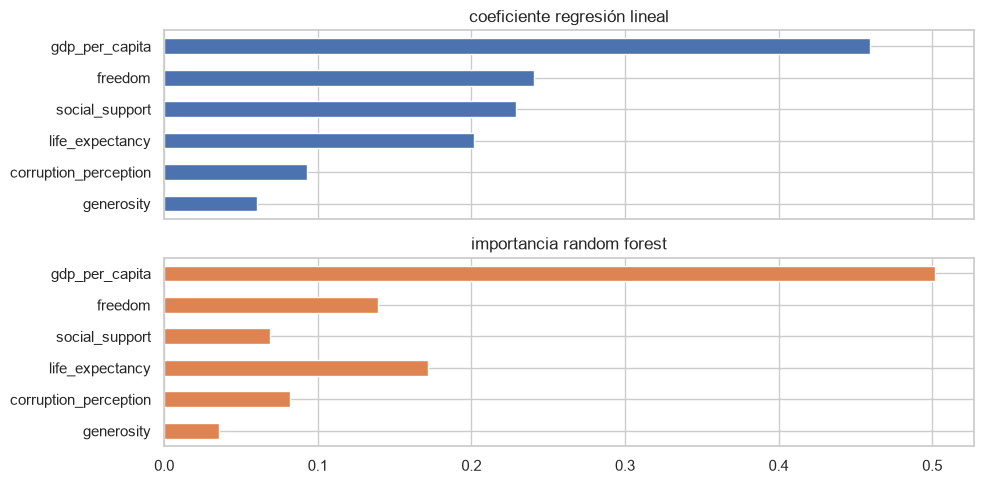

In [20]:
comparacion = pd.DataFrame({
    "coeficiente regresión lineal": coefs,
    "importancia random forest": pd.Series(imp, index=FEATURES),
}).sort_values("coeficiente regresión lineal")

comparacion.plot(kind="barh", subplots=True, figsize=(10, 5), legend=False)
plt.tight_layout()
guardar_figura("06_coeficientes_importancias")
plt.show()

pruebo con anova si las variables cambian de media entre años. Si el puntaje se mantiene igual pero las variables se mueven, lo más probable es que haya cambiado cómo se miden

,F_anova,p_anova
variable,,
happiness_score,0.04,9.96e-01
gdp_per_capita,2.80,2.51e-02
social_support,65.22,1.41e-47
life_expectancy,13.46,1.29e-10
freedom,7.16,1.15e-05
generosity,11.78,2.71e-09
corruption_perception,3.10,1.50e-02


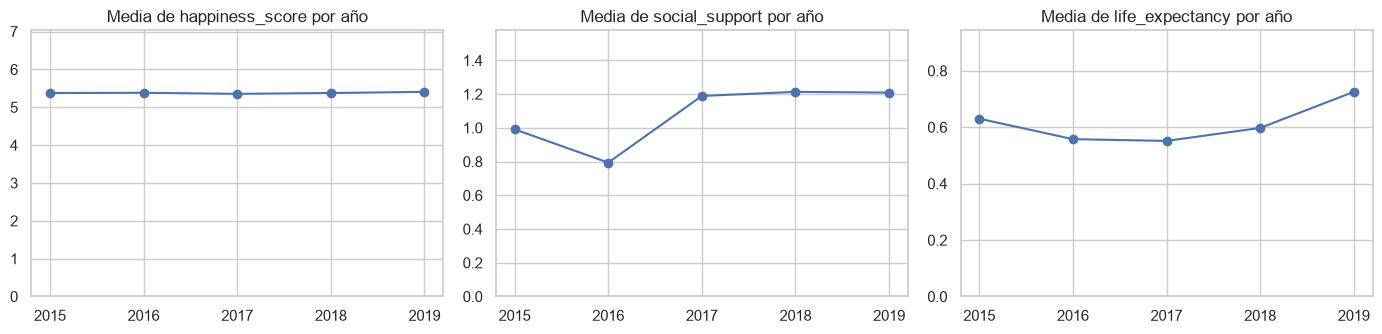

In [21]:
from scipy import stats

filas = []
for col in [TARGET] + FEATURES:
    por_anio = [df_all.loc[df_all["year"] == a, col].dropna() for a in sorted(df_all["year"].unique())]
    F, p_anova = stats.f_oneway(*por_anio)
    filas.append({"variable": col, "F_anova": F, "p_anova": p_anova})

tabla_anova = pd.DataFrame(filas).set_index("variable")
display(tabla_anova.style.format({"F_anova": "{:.2f}", "p_anova": "{:.2e}"}))

medias = df_all.groupby("year")[[TARGET, "social_support", "life_expectancy"]].mean()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, col in zip(ax, medias.columns):
    a.plot(medias.index, medias[col], marker="o")
    a.set_xticks(medias.index)
    a.set_ylim(0, medias[col].max() * 1.3)
    a.set_title(f"Media de {col} por año")
plt.tight_layout()
guardar_figura("08_medias_por_anio")
plt.show()

el puntaje promedio no cambia entre años, con p de 0.996, pero todas las variables sí se mueven. El caso más fuerte es el apoyo social, con p de 1.4e-47, seguido por la esperanza de vida con p de 1.3e-10 y la generosidad con 2.7e-9. O sea que los países no cambiaron tanto, cambió la escala de las variables. Por eso más adelante meto el año en el modelo

calculo el VIF y el KMO para saber si la correlación entre pib, esperanza de vida y apoyo social es un problema para el modelo

In [22]:
imp_med = SimpleImputer(strategy="median").fit(X_train)
Xtr = pd.DataFrame(imp_med.transform(X_train), columns=FEATURES, index=X_train.index)
Xtr_z = (Xtr - Xtr.mean()) / Xtr.std()

def calcular_vif(Xz):
    salida = {}
    for c in Xz.columns:
        otras = [k for k in Xz.columns if k != c]
        A = np.c_[np.ones(len(Xz)), Xz[otras].values]
        b, *_ = np.linalg.lstsq(A, Xz[c].values, rcond=None)
        r2 = 1 - ((Xz[c].values - A @ b) ** 2).sum() / ((Xz[c].values - Xz[c].mean()) ** 2).sum()
        salida[c] = 1 / (1 - r2)
    return pd.Series(salida, name="VIF")

display(calcular_vif(Xtr_z).round(2))

gdp_per_capita           3.06
social_support           1.73
life_expectancy          2.96
freedom                  1.69
generosity               1.21
corruption_perception    1.44
Name: VIF, dtype: float64

In [23]:
R = Xtr_z.corr().values
Ri = np.linalg.inv(R)
parc = -Ri / np.sqrt(np.outer(np.diag(Ri), np.diag(Ri)))
off = ~np.eye(len(R), dtype=bool)
kmo_global = (R[off] ** 2).sum() / ((R[off] ** 2).sum() + (parc[off] ** 2).sum())
kmo_var = pd.Series(
    [(R[i, off[i]] ** 2).sum() / ((R[i, off[i]] ** 2).sum() + (parc[i, off[i]] ** 2).sum()) for i in range(len(R))],
    index=FEATURES, name="KMO")

n_, p_ = Xtr_z.shape
chi2 = -(n_ - 1 - (2 * p_ + 5) / 6) * np.log(np.linalg.det(R))
p_bartlett = 1 - stats.chi2.cdf(chi2, p_ * (p_ - 1) / 2)
print(f"KMO global: {kmo_global:.3f}")
print(f"Bartlett: chi2 = {chi2:.1f}, p = {p_bartlett:.2e}")
display(kmo_var.round(3))

KMO global: 0.679
Bartlett: chi2 = 1351.6, p = 0.00e+00


gdp_per_capita           0.658
social_support           0.768
life_expectancy          0.680
freedom                  0.656
generosity               0.636
corruption_perception    0.654
Name: KMO, dtype: float64

el VIF queda entre 1.2 y 3.1, así que la multicolinealidad es leve. El KMO global da 0.68, un nivel aceptable, y por variable va de 0.64 a 0.77. La prueba de Bartlett rechaza que la matriz de correlaciones sea identidad, o sea que las variables sí están relacionadas entre sí, pero no al punto de estorbar en la regresión

ajusto la regresión lineal por mínimos cuadrados sobre train, con las variables estandarizadas, para ver el tamaño de cada coeficiente, su p valor y su intervalo

In [24]:
def ols_clasico(X, y, nombres):
    """regresión por mínimos cuadrados con errores estándar clásicos"""
    A = np.c_[np.ones(len(X)), X]
    n, k = A.shape
    XtXi = np.linalg.inv(A.T @ A)
    beta = XtXi @ A.T @ y
    e = y - A @ beta
    ee = np.sqrt(np.diag((e ** 2).sum() / (n - k) * XtXi))
    t = beta / ee
    p = 2 * (1 - stats.t.cdf(np.abs(t), df=n - k))
    margen = stats.t.ppf(0.975, n - k) * ee
    tabla = pd.DataFrame({"coef": beta, "error_estandar": ee, "t": t, "p": p,
                          "IC95_inf": beta - margen, "IC95_sup": beta + margen},
                         index=["constante"] + nombres)
    r2_ = 1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return tabla, e, A, r2_

tabla_ols, resid_train, A_train, r2_train = ols_clasico(Xtr_z.values, y_train.values, FEATURES)
display(tabla_ols.round(4))
print("R2 en train:", round(r2_train, 4))

,coef,error_estandar,t,p,IC95_inf,IC95_sup
constante,5.3687,0.0216,248.2718,0.0000,5.3263,5.4112
gdp_per_capita,0.4597,0.0379,12.1440,0.0000,0.3853,0.5340
social_support,0.2295,0.0285,8.0626,0.0000,0.1736,0.2854
life_expectancy,0.2021,0.0373,5.4250,0.0000,0.1290,0.2753
freedom,0.2411,0.0281,8.5706,0.0000,0.1858,0.2963
generosity,0.0602,0.0238,2.5269,0.0118,0.0134,0.1069
corruption_perception,0.0932,0.0260,3.5867,0.0004,0.0422,0.1442


R2 en train: 0.7591


el modelo explica el 76 por ciento de la varianza en train. Las seis variables salen significativas, con el pib como la más fuerte, con coeficiente de 0.46 y la generosidad como la más débil, con 0.06 y p de 0.012. Uso los p valores para interpretar el modelo y no para sacar variables. Hay que leerlos con cuidado, porque un mismo país aparece varias veces y los errores de sus filas se parecen, así que los p valores salen algo optimistas, y por eso la división es por país

reviso los supuestos de la regresión con el QQ plot de los residuos y con los residuos contra el valor ajustado

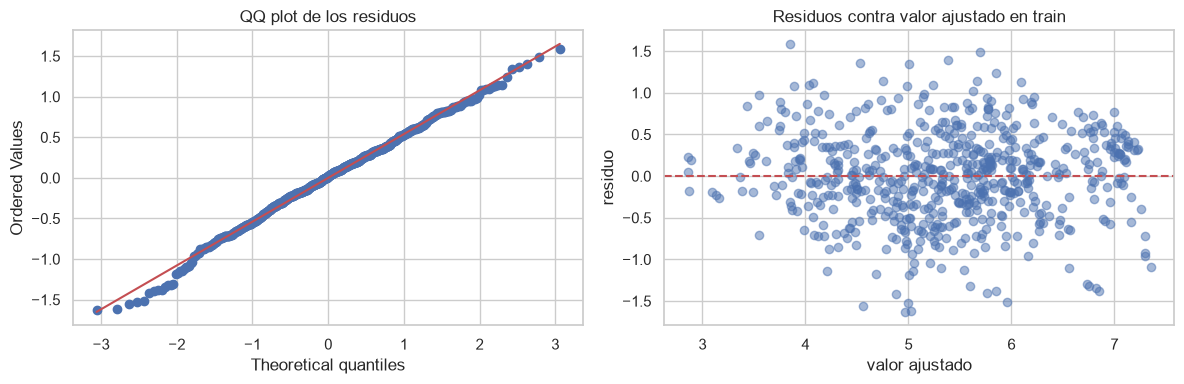

In [25]:
ajustado = y_train.values - resid_train
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
stats.probplot(resid_train, dist="norm", plot=ax[0])
ax[0].set_title("QQ plot de los residuos")
ax[1].scatter(ajustado, resid_train, alpha=0.5)
ax[1].axhline(0, color="r", linestyle="--")
ax[1].set_title("Residuos contra valor ajustado en train")
ax[1].set_xlabel("valor ajustado")
ax[1].set_ylabel("residuo")
plt.tight_layout()
guardar_figura("09_supuestos_residuos")
plt.show()

el QQ plot muestra residuos pegados a la línea, con una leve desviación en la cola izquierda, y en los residuos contra el ajustado no se ve una forma clara, solo unos pocos residuos negativos grandes en los puntajes altos. Es razonable seguir con la regresión lineal

meto el año en el pipeline con codificación one hot, así el modelo aprende un ajuste por año que absorbe el cambio de escala. Comparo tres modelos en 40 particiones por país distintas y no en una sola, y cuento en cuántas gana cada uno al base

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import GroupShuffleSplit

COLS = FEATURES + ["year"]
X_all = df_all[COLS]

def armar_pipeline(algoritmo, con_anio):
    num = Pipeline([("imputador", SimpleImputer(strategy="median")), ("escalador", StandardScaler())])
    bloques = [("num", num, FEATURES)]
    if con_anio:
        bloques.append(("anio", OneHotEncoder(drop="first", handle_unknown="ignore"), ["year"]))
    return Pipeline([("pre", ColumnTransformer(bloques)), ("modelo", algoritmo)])

candidatos = {
    "Lineal base": lambda: armar_pipeline(LinearRegression(), False),
    "Lineal con año": lambda: armar_pipeline(LinearRegression(), True),
    "Random Forest con año": lambda: armar_pipeline(RandomForestRegressor(n_estimators=200, random_state=42), True),
}

# 40 particiones distintas por país, así la comparación no depende de una sola partición
particiones = list(GroupShuffleSplit(n_splits=40, test_size=0.2, random_state=0).split(X_all, y, groups=grupos))
mae, r2 = {n: [] for n in candidatos}, {n: [] for n in candidatos}
for tr_, te_ in particiones:
    for nombre, fabrica in candidatos.items():
        p = fabrica().fit(X_all.iloc[tr_], y.iloc[tr_])
        pred = p.predict(X_all.iloc[te_])
        mae[nombre].append(mean_absolute_error(y.iloc[te_], pred))
        r2[nombre].append(r2_score(y.iloc[te_], pred))

resumen = pd.DataFrame({
    "MAE_medio": {n: np.mean(v) for n, v in mae.items()},
    "MAE_desvio": {n: np.std(v) for n, v in mae.items()},
    "R2_medio": {n: np.mean(v) for n, v in r2.items()},
    "R2_desvio": {n: np.std(v) for n, v in r2.items()},
})
display(resumen.round(4))

# en cuántas de las 40 particiones mejora cada modelo al base
for nombre in ["Lineal con año", "Random Forest con año"]:
    mejor = int((np.array(mae[nombre]) < np.array(mae["Lineal base"])).sum())
    print(f"{nombre} contra Lineal base: menor MAE en {mejor} de 40 particiones")

,MAE_medio,MAE_desvio,R2_medio,R2_desvio
Lineal base,0.4412,0.0538,0.7410,0.0703
Lineal con año,0.4208,0.0487,0.7631,0.0625
Random Forest con año,0.4547,0.0593,0.7245,0.0753


Lineal con año contra Lineal base: menor MAE en 34 de 40 particiones
Random Forest con año contra Lineal base: menor MAE en 10 de 40 particiones


la regresión lineal con año baja el MAE medio de 0.441 a 0.421 y sube el R2 de 0.741 a 0.763, y mejora en 34 de las 40 particiones. El random forest con año solo le gana al base en 10. El random forest con año queda peor que la lineal base, con MAE de 0.455, así que me quedo con la regresión lineal con año como modelo final

evalúo el modelo final en el mismo test de antes

In [27]:
MODELO_FINAL = "Regresión Lineal con año"
pipe_final = armar_pipeline(LinearRegression(), True)
pipe_final.fit(X_all.iloc[idx_train], y_train)
pred_final = pipe_final.predict(X_all.iloc[idx_test])
pred_base = predicciones["Regresión Lineal"]

def metricas_modelo(real, pred, n_predictores):
    mse = mean_squared_error(real, pred)
    r2_ = r2_score(real, pred)
    return {
        "MAE": mean_absolute_error(real, pred), "MSE": mse, "RMSE": np.sqrt(mse),
        "R2": r2_, "R2_ajustado": r2_ajustado(r2_, len(real), n_predictores),
    }

n_pred_final = pipe_final.named_steps["pre"].transform(X_all.iloc[idx_test]).shape[1]
tabla_final = pd.DataFrame({
    "Regresión Lineal base": metricas_modelo(y_test, pred_base, len(FEATURES)),
    MODELO_FINAL: metricas_modelo(y_test, pred_final, n_pred_final),
}).T
display(tabla_final.round(4))

,MAE,MSE,RMSE,R2,R2_ajustado
Regresión Lineal base,0.4502,0.3485,0.5903,0.7737,0.7645
Regresión Lineal con año,0.4276,0.3185,0.5644,0.7931,0.7788


en el test el MAE baja de 0.450 a 0.428 y el R2 sube de 0.774 a 0.793, con R2 ajustado de 0.779. La mejora se ve también en las 40 particiones, pero con solo 33 países de test cualquier métrica depende bastante de cuáles caen ahí

pruebo una validación en el tiempo. Entreno con los años anteriores y predigo el año siguiente. Comparo los modelos con dos referencias, la persistencia, que repite el puntaje del año anterior, y la suavización exponencial simple por país, con alpha elegido dentro del train. No hago un modelo de series de tiempo completo porque cada país tiene solo cinco puntos

In [28]:
def suavizacion(train, alpha):
    """suavización exponencial simple por país, devuelve el nivel final y el error de un paso adelante"""
    niveles, err = {}, []
    for pais, g in train.sort_values("year").groupby("country"):
        v = g[TARGET].values
        nivel = v[0]
        for x in v[1:]:
            err.append(x - nivel)
            nivel = alpha * x + (1 - alpha) * nivel
        niveles[pais] = nivel
    return niveles, np.mean(np.square(err))

def z_por_anio(d):
    """estandarizo cada variable con la media y la desviación de su propio año"""
    d = d.copy()
    for a in d["year"].unique():
        m = d["year"] == a
        d.loc[m, FEATURES] = (d.loc[m, FEATURES] - d.loc[m, FEATURES].mean()) / d.loc[m, FEATURES].std()
    return d

filas = []
for T in (2017, 2018, 2019):
    entrena = df_all[df_all["year"] < T]
    prueba = df_all[df_all["year"] == T]

    # persistencia: predecir que el puntaje es el mismo del año anterior
    previo = df_all[df_all["year"] == T - 1].set_index("country")[TARGET]
    pers = prueba["country"].map(previo)
    hay = pers.notna()

    fila = {"año a predecir": T, "países": len(prueba),
            "persistencia": mean_absolute_error(prueba.loc[hay, TARGET], pers[hay])}

    # suavización exponencial: elijo alpha con el error de un paso adelante dentro del train
    alphas = np.arange(0.1, 1.01, 0.1)
    alpha = alphas[int(np.argmin([suavizacion(entrena, a)[1] for a in alphas]))]
    niveles, _ = suavizacion(entrena, alpha)
    se = prueba["country"].map(niveles)
    ok = se.notna()
    fila["suavización exp"] = mean_absolute_error(prueba.loc[ok, TARGET], se[ok])
    fila["alpha"] = alpha

    p = armar_pipeline(LinearRegression(), False).fit(entrena[COLS], entrena[TARGET])
    fila["lineal base"] = mean_absolute_error(prueba[TARGET], p.predict(prueba[COLS]))

    p = armar_pipeline(LinearRegression(), True).fit(entrena[COLS], entrena[TARGET])
    fila["lineal con año"] = mean_absolute_error(prueba[TARGET], p.predict(prueba[COLS]))

    ent_z, pru_z = z_por_anio(entrena), z_por_anio(prueba)
    p = armar_pipeline(LinearRegression(), False).fit(ent_z[COLS], ent_z[TARGET])
    fila["lineal z por año"] = mean_absolute_error(pru_z[TARGET], p.predict(pru_z[COLS]))
    filas.append(fila)

display(pd.DataFrame(filas).set_index("año a predecir").round(3))

c:\Users\ASUS\Documents\workshop3-etl-kafka\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\ASUS\Documents\workshop3-etl-kafka\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\ASUS\Documents\workshop3-etl-kafka\venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,países,persistencia,suavización exp,alpha,lineal base,lineal con año,lineal z por año
año a predecir,,,,,,,
2017,155,0.124,0.233,0.1,0.509,0.431,0.376
2018,156,0.137,0.138,1.0,0.424,0.460,0.402
2019,156,0.135,0.138,1.0,0.424,0.464,0.417


las referencias ganan por mucho. La persistencia y la suavización exponencial dan MAE de 0.12 a 0.14, y los modelos con variables dan de 0.38 a 0.51, porque el puntaje de un país casi no cambia de un año a otro. En 2018 y 2019 el alpha elegido es 1, o sea que la suavización queda igual a la persistencia, y en 2017 con solo dos años de historia elige 0.1 y le va peor. Eso no invalida el modelo, resuelve otro problema. Sirve para explicar qué variables mueven el puntaje y para estimarlo cuando no hay puntaje previo, pero no para pronosticar el año que viene. Otro hallazgo es que el año como categoría falla al predecir un año nuevo, con 0.460 y 0.464 en 2018 y 2019 contra 0.424 del base, porque un año que no vio queda tratado como el año de referencia. Estandarizar por año funciona mejor ahí, con 0.376, 0.402 y 0.417. En este proyecto los años de test son los mismos de train, así que dejo el año como categoría, y si el modelo tuviera que predecir años futuros usaría la estandarización por año

reviso dónde se equivoca el modelo final, por país y por año, y lo comparo con el base

Los 10 errores más grandes en test:


,country,year,score_real,score_predicho,error,error_abs
672,Botswana,2019,3.488,5.334,-1.846,1.846
564,Botswana,2018,3.590,5.393,-1.803,1.803
463,Botswana,2017,3.766,5.417,-1.651,1.651
306,Botswana,2016,3.974,5.484,-1.510,1.510
779,Tanzania,2019,3.231,4.563,-1.332,1.332
624,Tanzania,2018,3.303,4.615,-1.312,1.312
468,Tanzania,2017,3.349,4.568,-1.219,1.219
2,Israel,2015,7.278,6.184,1.094,1.094
207,Brazil,2016,6.952,5.860,1.092,1.092
616,Myanmar,2018,4.308,5.400,-1.092,1.092


Error por año en test:


,count,mean
year,,
2015,32,0.402
2016,32,0.423
2017,30,0.428
2018,30,0.442
2019,32,0.445


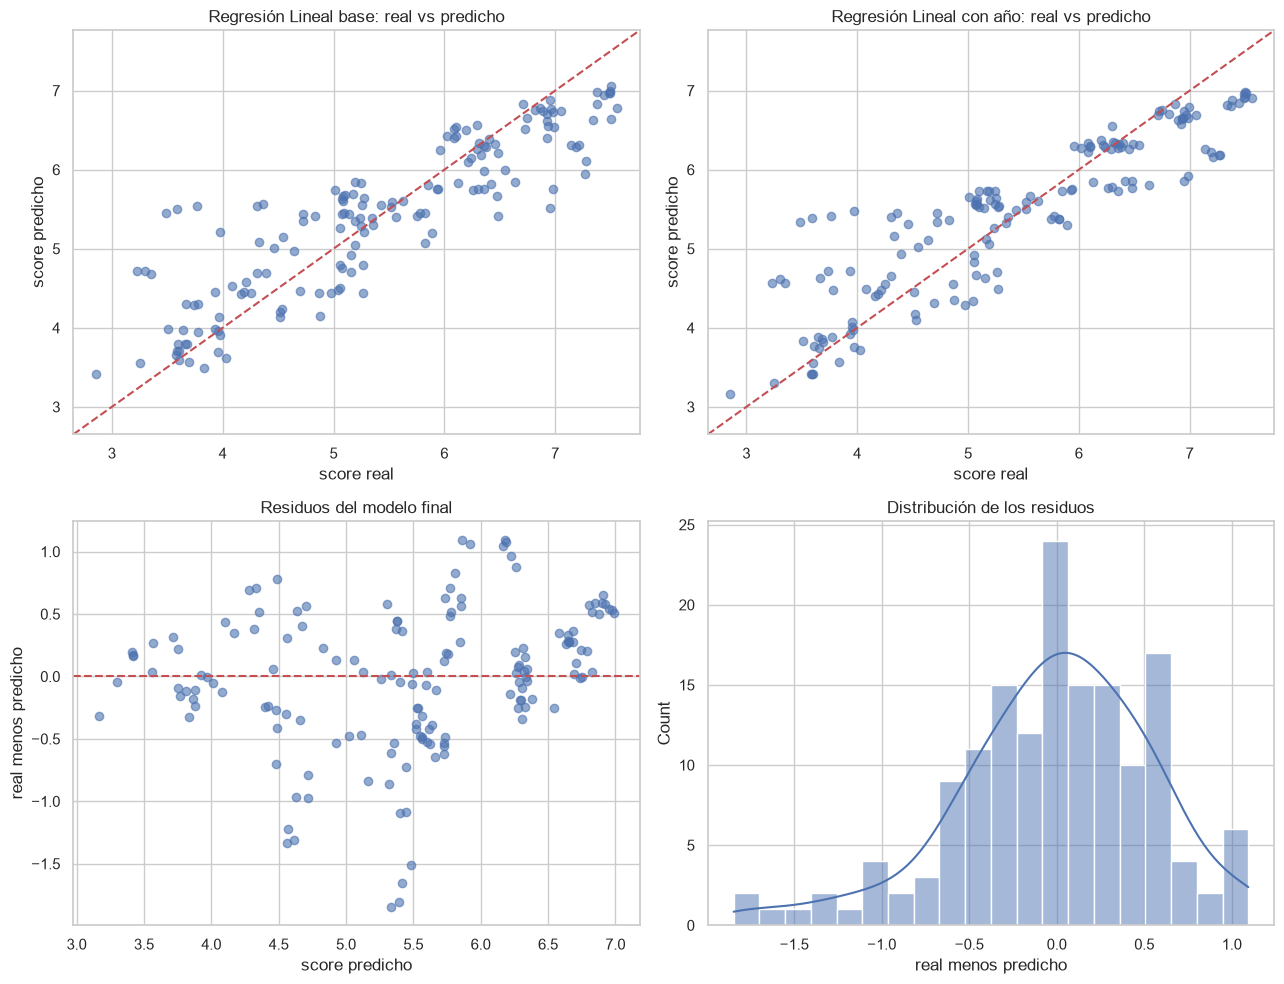

In [29]:
resultado = df_all.iloc[idx_test][["country", "year"]].copy()
resultado["score_real"] = y_test.values
resultado["score_predicho"] = pred_final
resultado["error"] = resultado["score_real"] - resultado["score_predicho"]
resultado["error_abs"] = resultado["error"].abs()

print("Los 10 errores más grandes en test:")
display(resultado.sort_values("error_abs", ascending=False).head(10).round(3))

print("Error por año en test:")
display(resultado.groupby("year")["error_abs"].agg(["count", "mean"]).round(3))

fig, ax = plt.subplots(2, 2, figsize=(13, 10))
lims = [y_test.min() - 0.2, y_test.max() + 0.2]

for a, (nombre, pred) in zip(ax[0], {"Regresión Lineal base": pred_base, MODELO_FINAL: pred_final}.items()):
    a.scatter(y_test, pred, alpha=0.6)
    a.plot(lims, lims, "r--")
    a.set_xlim(lims)
    a.set_ylim(lims)
    a.set_title(f"{nombre}: real vs predicho")
    a.set_xlabel("score real")
    a.set_ylabel("score predicho")

ax[1, 0].scatter(pred_final, resultado["error"], alpha=0.6)
ax[1, 0].axhline(0, color="r", linestyle="--")
ax[1, 0].set_title("Residuos del modelo final")
ax[1, 0].set_xlabel("score predicho")
ax[1, 0].set_ylabel("real menos predicho")

sns.histplot(resultado["error"], bins=20, kde=True, ax=ax[1, 1])
ax[1, 1].set_title("Distribución de los residuos")
ax[1, 1].set_xlabel("real menos predicho")

plt.tight_layout()
guardar_figura("05_real_vs_predicho_residuos")
plt.show()

el error medio es parecido en los cinco años, entre 0.40 en 2015 y 0.45 en 2019. Botswana aparece cuatro veces entre los diez errores más grandes y Tanzania tres, siempre sobreestimados por más de un punto. Eso indica que el modelo no captura algo propio de esos países, y como tienen varias filas en test el mismo error se repite

miro los coeficientes del modelo final. Las variables están estandarizadas, así que se pueden comparar entre sí, y los del año se leen contra 2015

gdp_per_capita           0.3614
social_support           0.3836
life_expectancy          0.2130
freedom                  0.2428
generosity               0.0390
corruption_perception    0.0872
year_2016                0.2990
year_2017               -0.2497
year_2018               -0.2482
year_2019               -0.2414
dtype: float64

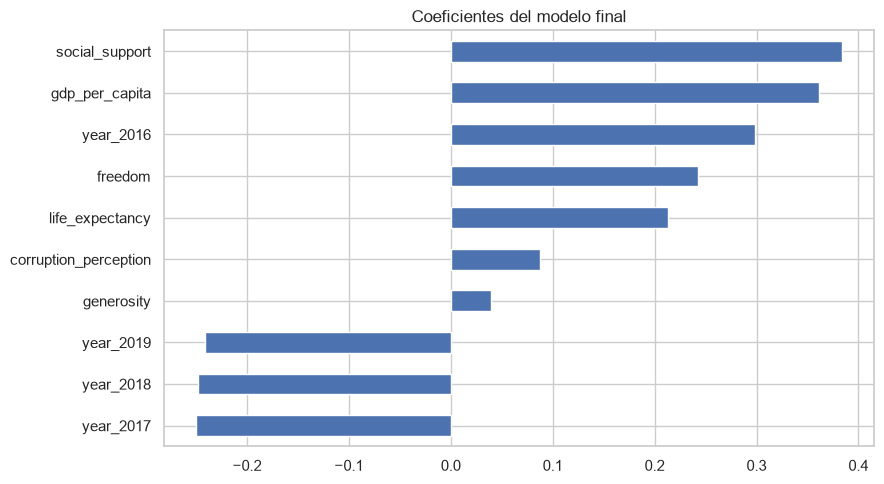

In [30]:
nombres = pipe_final.named_steps["pre"].get_feature_names_out()
coef_final = pd.Series(pipe_final.named_steps["modelo"].coef_, index=[n.split("__")[1] for n in nombres])
display(coef_final.round(4))

coef_final.sort_values().plot(kind="barh", figsize=(9, 5), title="Coeficientes del modelo final")
plt.tight_layout()
guardar_figura("10_coeficientes_modelo_final")
plt.show()

el apoyo social y el pib son las que más pesan, con 0.38 y 0.36, seguidas por la libertad con 0.24 y la esperanza de vida con 0.21. Con el año en el modelo el apoyo social sube de 0.23 a 0.38, probablemente porque antes parte de su efecto se mezclaba con el cambio de escala. Los efectos de año se leen contra 2015. El 2016 queda 0.30 arriba y del 2017 al 2019 quedan cerca de 0.25 abajo, que es el ajuste que compensa el salto del apoyo social entre 2016 y 2017

guardo el pipeline completo con joblib, con el imputador, el escalador y la codificación del año adentro, porque si guardara solo el modelo tendría que repetir a mano el preprocesamiento cada vez que lo use. Le sumo unos metadatos mínimos

In [31]:
import joblib
from datetime import datetime

artefacto = {
    "pipeline": pipe_final,
    "metadata": {
        "algoritmo": "LinearRegression con año categórico",
        "version": "2.0",
        "features": COLS,
        "target": TARGET,
        "fecha_creacion": datetime.now().isoformat(timespec="seconds"),
        "metricas_test": tabla_final.loc[MODELO_FINAL].round(4).to_dict(),
    },
}

os.makedirs("models", exist_ok=True)
joblib.dump(artefacto, "models/modelo_felicidad.joblib")
print("Modelo guardado en models/modelo_felicidad.joblib")
print(artefacto["metadata"])

Modelo guardado en models/modelo_felicidad.joblib
{'algoritmo': 'LinearRegression con año categórico', 'version': '2.0', 'features': ['gdp_per_capita', 'social_support', 'life_expectancy', 'freedom', 'generosity', 'corruption_perception', 'year'], 'target': 'happiness_score', 'fecha_creacion': '2026-11-17T02:07:57', 'metricas_test': {'MAE': 0.4276, 'MSE': 0.3185, 'RMSE': 0.5644, 'R2': 0.7931, 'R2_ajustado': 0.7788}}


cargo las predicciones del test en una base SQLite y las vuelvo a leer con una consulta para confirmar que quedaron bien

In [32]:
from database import guardar_predicciones, leer_tabla

tabla_db = resultado.drop(columns="error_abs").copy()
tabla_db["modelo"] = MODELO_FINAL
tabla_db["fecha_carga"] = datetime.now().isoformat(timespec="seconds")

guardar_predicciones(tabla_db)

print("Filas cargadas:")
display(leer_tabla("SELECT COUNT(*) AS filas FROM predicciones"))

print("Los 5 países con más error:")
display(leer_tabla(
    "SELECT country, year, score_real, score_predicho, error "
    "FROM predicciones ORDER BY ABS(error) DESC LIMIT 5"
).round(3))

Filas cargadas:


,filas
0,156


Los 5 países con más error:


,country,year,score_real,score_predicho,error
0,Botswana,2019,3.488,5.334,-1.846
1,Botswana,2018,3.590,5.393,-1.803
2,Botswana,2017,3.766,5.417,-1.651
3,Botswana,2016,3.974,5.484,-1.510
4,Tanzania,2019,3.231,4.563,-1.332


simulo cómo se usaría el modelo después. Cargo el archivo guardado en una sección aparte, armo un registro nuevo con su año, reviso que traiga las columnas esperadas y predigo

In [33]:
art = joblib.load("models/modelo_felicidad.joblib")
modelo_cargado = art["pipeline"]
esperadas = art["metadata"]["features"]

nuevo = pd.DataFrame([{
    "gdp_per_capita": 1.30,
    "social_support": 1.40,
    "life_expectancy": 0.90,
    "freedom": 0.50,
    "generosity": 0.20,
    "corruption_perception": 0.10,
    "year": 2019,
}])

faltan = set(esperadas) - set(nuevo.columns)
assert not faltan, f"Faltan columnas: {faltan}"
nuevo = nuevo[esperadas]

print(nuevo.dtypes)
print("Score predicho:", round(float(modelo_cargado.predict(nuevo)[0]), 3))

gdp_per_capita           float64
social_support           float64
life_expectancy          float64
freedom                  float64
generosity               float64
corruption_perception    float64
year                       int64
dtype: object
Score predicho: 6.304


conclusiones. El modelo final es una regresión lineal con imputación por mediana, escalado y el año como categoría. En el test de 33 países llega a un MAE de 0.43 y un R2 de 0.79, y le gana al modelo base y al random forest en las 40 particiones distintas que probé. El pib y el apoyo social son las variables que más pesan.

lo que aportó la estadística. El anova mostró que las variables cambian de escala entre años mientras el puntaje no, y eso justifica el año en el modelo. El VIF y el KMO mostraron multicolinealidad leve y la regresión mostró que las seis variables aportan, con el pib y el apoyo social al frente. Como un mismo país aparece varias veces, divido siempre por país y repito la comparación en 40 particiones, porque con 33 países de test una sola métrica es incierta.

limitaciones. Solo hay seis variables y cinco años por país, y el panel no está balanceado. El modelo no sirve para pronosticar el año siguiente, porque repetir el puntaje del año anterior o suavizarlo lo supera por mucho. Los seis factores del informe son contribuciones estimadas por los autores y no mediciones directas, así que parte del buen ajuste viene de ahí. El año como categoría no funciona para años que el modelo no vio.

mejoras posibles. Estandarizar por año si hubiera que predecir años nuevos, probar ridge o lasso, aplicar suavización exponencial para pronosticar, gradient boosting con búsqueda de hiperparámetros, sumar la región para los años que la tienen y revisar con más cuidado países como Botswana y Tanzania, donde el error es grande y se repite todos los años.